In [10]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np
import re

sns.set(style='whitegrid')

In [11]:
# === Path setup ===
base_path = Path("../dataset/v2")
label_path = base_path / "train" / "labels"
image_path = base_path / "train" / "images"

annotations = []
skipped = []

In [12]:
# === Roboflow-style filename resolver ===
def resolve_image_file(label_file):
    stem = label_file.stem
    candidates = list(image_path.glob(f"{stem}.*"))
    return candidates[0] if candidates else None

# === Parse labels ===
for label_file in label_path.glob("*.txt"):
    try:
        with open(label_file) as f:
            lines = f.readlines()
        
        image_file = resolve_image_file(label_file)
        if image_file is None:
            skipped.append((label_file.name, "Image not found (Roboflow style)"))
            continue
        
        img = Image.open(image_file)
        width, height = img.size

        for line in lines:
            parts = line.strip().split()
            if len(parts) != 5:
                skipped.append((label_file.name, "Invalid label format"))
                continue

            cls, x, y, w, h = map(float, parts)
            annotations.append({
                "file": label_file.stem,
                "class": int(cls),
                "x": x, "y": y, "w": w, "h": h,
                "img_w": width,
                "img_h": height
            })
    except Exception as e:
        skipped.append((label_file.name, str(e)))

In [13]:
# === To DataFrame ===
df = pd.DataFrame(annotations)
print(f"Total valid annotations: {len(df)}")
print(f"Total skipped files: {len(skipped)}")
if skipped:
    print("🔍 Skipped examples:")
    for entry in skipped[:5]:
        print("  -", entry)

# === Derived pixel-level metrics ===
if not df.empty:
    df["bbox_w_px"] = df["w"] * df["img_w"]
    df["bbox_h_px"] = df["h"] * df["img_h"]
    df["area"] = df["bbox_w_px"] * df["bbox_h_px"]
    df["aspect_ratio"] = df["bbox_w_px"] / df["bbox_h_px"]

Total valid annotations: 16616
Total skipped files: 0


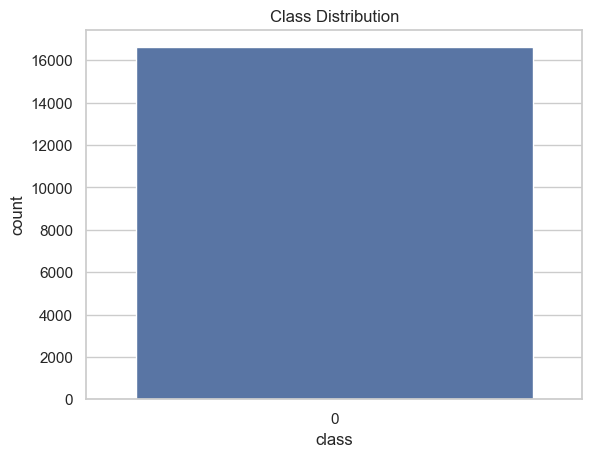

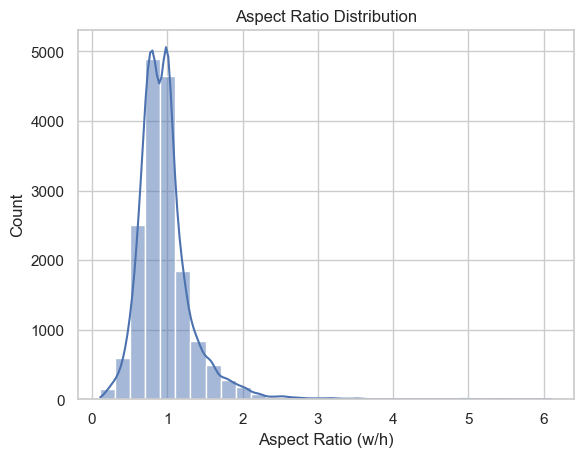

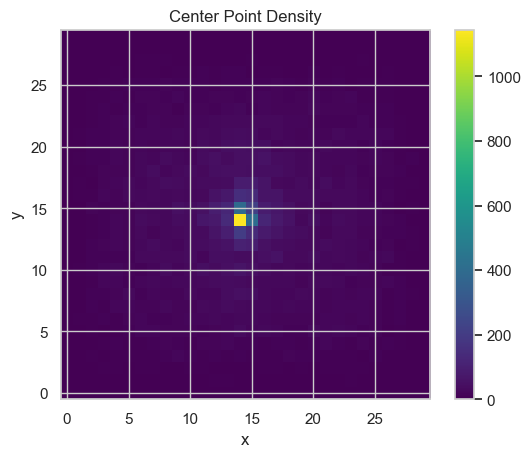

In [14]:
# === Visuals ===
if not df.empty:
    sns.countplot(x="class", data=df)
    plt.title("Class Distribution")
    plt.show()

    sns.histplot(df["aspect_ratio"], bins=30, kde=True)
    plt.title("Aspect Ratio Distribution")
    plt.xlabel("Aspect Ratio (w/h)")
    plt.show()

    heatmap, xedges, yedges = np.histogram2d(df["x"], df["y"], bins=30)
    plt.imshow(heatmap.T, origin="lower", cmap="viridis")
    plt.title("Center Point Density")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.colorbar()
    plt.show()